In [ ]:
# ============================================================
# DOSM DATATHON 2026
# SUSTAINABLE TOURISM READINESS IN MALAYSIA
# ============================================================

!pip -q install pandas numpy matplotlib seaborn scikit-learn openpyxl pyarrow requests

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import os
import warnings

warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    silhouette_score,
    classification_report,
    confusion_matrix,
    accuracy_score
)
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)

print("Environment ready.")

Environment ready.


In [ ]:
# ============================================================
# PROJECT FOLDERS
# ============================================================

os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
os.makedirs("models", exist_ok=True)

print("Folders created.")

Folders created.


In [ ]:
# ============================================================
# OFFICIAL OPENDOSM DATASETS
# ============================================================

URLS = {

    # Economic
    "gdp":
    "https://storage.dosm.gov.my/gdp/gdp_state_real_supply.csv",

    # Household income / poverty / inequality / expenditure
    "hies":
    "https://storage.dosm.gov.my/hies/hies_state.csv",

    # Labour
    "labour":
    "https://storage.dosm.gov.my/labour/lfs_state_sex.csv",

    # Population
    "population":
    "https://storage.dosm.gov.my/population/population_state.csv",

    # CPI
    "cpi":
    "https://storage.dosm.gov.my/cpi/cpi_2d_state.csv",

    # Environment
    "forest":
    "https://storage.data.gov.my/environment/forest_reserve_state.csv",

    "water_access":
    "https://storage.data.gov.my/water/water_access.csv",

    "water_consumption":
    "https://storage.data.gov.my/water/water_consumption.csv"
}

for name, url in URLS.items():
    print(name, ":", url)

gdp : https://storage.dosm.gov.my/gdp/gdp_state_real_supply.csv
hies : https://storage.dosm.gov.my/hies/hies_state.csv
labour : https://storage.dosm.gov.my/labour/lfs_state_sex.csv
population : https://storage.dosm.gov.my/population/population_state.csv
cpi : https://storage.dosm.gov.my/cpi/cpi_2d_state.csv
forest : https://storage.data.gov.my/environment/forest_reserve_state.csv
water_access : https://storage.data.gov.my/water/water_access.csv
water_consumption : https://storage.data.gov.my/water/water_consumption.csv


In [ ]:
# ============================================================
# DOWNLOAD DATA
# ============================================================

raw_data = {}

for name, url in URLS.items():

    try:

        print(f"Downloading {name}...")

        df = pd.read_csv(url)

        raw_data[name] = df

        df.to_csv(
            f"data/raw/{name}.csv",
            index=False
        )

        print(
            f"   âœ“ {name}: "
            f"{df.shape[0]:,} rows Ã— "
            f"{df.shape[1]} columns"
        )

    except Exception as e:

        print(
            f"   âœ— Failed: {name}"
        )

        print(e)

   âœ“ gdp: 2,163 rows Ã— 5 columns
   âœ“ hies: 32 rows Ã— 7 columns
   âœ“ labour: 1,732 rows Ã— 10 columns
   âœ“ population: 270,063 rows Ã— 6 columns
   âœ“ cpi: 44,800 rows Ã— 4 columns
   âœ“ forest: 323 rows Ã— 3 columns
   âœ“ water_access: 1,035 rows Ã— 4 columns
   âœ“ water_consumption: 600 rows Ã— 4 columns


In [ ]:
# ============================================================
# INSPECT DATA
# ============================================================

for name, df in raw_data.items():

    print("\n" + "=" * 70)

    print(name.upper())

    print("=" * 70)

    print(df.columns.tolist())

    display(df.head(3))


GDP
['series', 'date', 'state', 'sector', 'value']


,series,date,state,sector,value
0,abs,2015-01-01,Johor,p0,"110,002.221"
1,abs,2015-01-01,Johor,p1,"15,610.314"
2,abs,2015-01-01,Johor,p2,475.640



HIES
['date', 'state', 'income_mean', 'income_median', 'expenditure_mean', 'gini', 'poverty']


,date,state,income_mean,income_median,expenditure_mean,gini,poverty
0,2022-01-01,Johor,8517,6879,5342,0.366,4.600
1,2024-01-01,Johor,9484,7712,5927,0.348,2.500
2,2022-01-01,Kedah,5550,4402,3765,0.359,9.000



LABOUR
['state', 'sex', 'date', 'lf', 'lf_employed', 'lf_unemployed', 'lf_outside', 'p_rate', 'u_rate', 'ep_ratio']


...

,date,state,area
0,2003-01-01,Johor,"356,922.000"
1,2003-01-01,Kedah,"344,530.000"
2,2003-01-01,Kelantan,"629,687.000"



WATER_ACCESS
['state', 'strata', 'date', 'proportion']


,state,strata,date,proportion
0,Malaysia,overall,2000-01-01,92.000
1,Malaysia,overall,2001-01-01,92.700
2,Malaysia,overall,2002-01-01,93.200



WATER_CONSUMPTION
['state', 'sector', 'date', 'value']


,state,sector,date,value
0,Malaysia,domestic,2003-01-01,4394
1,Malaysia,domestic,2004-01-01,4770
2,Malaysia,domestic,2005-01-01,4992


In [ ]:
# ============================================================
# STATE STANDARDISATION
# ============================================================

STATE_MAP = {

    "Johor": "Johor",
    "Johore": "Johor",

    "Kedah": "Kedah",

    "Kelantan": "Kelantan",

    "Melaka": "Melaka",
    "Malacca": "Melaka",

    "Negeri Sembilan": "Negeri Sembilan",

    "Pahang": "Pahang",

    "Pulau Pinang": "Pulau Pinang",
    "Penang": "Pulau Pinang",

    "Perak": "Perak",

    "Perlis": "Perlis",

    "Selangor": "Selangor",

    "Terengganu": "Terengganu",

    "Sabah": "Sabah",

    "Sarawak": "Sarawak",

    "W.P. Kuala Lumpur": "W.P. Kuala Lumpur",
    "Kuala Lumpur": "W.P. Kuala Lumpur",

    "W.P. Putrajaya": "W.P. Putrajaya",
    "Putrajaya": "W.P. Putrajaya",

    "W.P. Labuan": "W.P. Labuan",
    "Labuan": "W.P. Labuan"
}


def clean_state_column(df):

    df = df.copy()

    if "state" in df.columns:

        df["state"] = (
            df["state"]
            .astype(str)
            .str.strip()
            .replace(STATE_MAP)
        )

    return df


for name in raw_data:

    raw_data[name] = clean_state_column(
        raw_data[name]
    )

print("State names standardised.")

State names standardised.


In [ ]:
# ============================================================
# DATE STANDARDISATION
# ============================================================

def add_year(df):

    df = df.copy()

    if "date" in df.columns:

        df["date"] = pd.to_datetime(
            df["date"],
            errors="coerce"
        )

        df["year"] = df["date"].dt.year

    return df


for name in raw_data:

    raw_data[name] = add_year(
        raw_data[name]
    )

In [ ]:
hies = raw_data["hies"].copy()

print(hies.columns.tolist())

display(hies.head())

['date', 'state', 'income_mean', 'income_median', 'expenditure_mean', 'gini', 'poverty', 'year']


,date,state,income_mean,income_median,expenditure_mean,gini,poverty,year
0,2022-01-01,Johor,8517,6879,5342,0.366,4.600,2022
1,2024-01-01,Johor,9484,7712,5927,0.348,2.500,2024
2,2022-01-01,Kedah,5550,4402,3765,0.359,9.000,2022
3,2024-01-01,Kedah,5793,4895,4028,0.334,8.400,2024
4,2022-01-01,Kelantan,4885,3614,3505,0.385,13.200,2022


In [ ]:
# ============================================================
# HIES 2022
# ============================================================

hies_2022 = hies[
    hies["year"] == 2022
].copy()

print(
    "HIES 2022:",
    hies_2022.shape
)

display(hies_2022.head())

HIES 2022: (16, 8)


,date,state,income_mean,income_median,expenditure_mean,gini,poverty,year
0,2022-01-01,Johor,8517,6879,5342,0.366,4.600,2022
2,2022-01-01,Kedah,5550,4402,3765,0.359,9.000,2022
4,2022-01-01,Kelantan,4885,3614,3505,0.385,13.200,2022
6,2022-01-01,Melaka,8057,6210,5707,0.370,4.200,2022
8,2022-01-01,Negeri Sembilan,6788,5226,4678,0.369,4.400,2022


In [ ]:
# ============================================================
# POPULATION
# ============================================================

population = raw_data["population"].copy()

population_2022 = population[
    (population["year"] == 2022) &
    (population["sex"] == "both") &
    (population["age"] == "overall") &
    (population["ethnicity"] == "overall")
].copy()

population_2022 = population_2022[
    ["state", "population"]
]

display(population_2022.head())

,state,population
15819,Johor,"4,028.300"
33633,Kedah,"2,163.100"
51447,Kelantan,"1,830.600"
69261,Melaka,"1,008.600"
87075,Negeri Sembilan,"1,207.900"


In [ ]:
# ============================================================
# GDP
# ============================================================

gdp = raw_data["gdp"].copy()

print(gdp.columns.tolist())

display(gdp.head())

for col in gdp.columns:

    if gdp[col].dtype == "object":

        print(
            "\nCOLUMN:",
            col
        )

        print(
            gdp[col]
            .dropna()
            .unique()[:30]
        )

['series', 'date', 'state', 'sector', 'value', 'year']


,series,date,state,sector,value,year
0,abs,2015-01-01,Johor,p0,"110,002.221",2015
1,abs,2015-01-01,Johor,p1,"15,610.314",2015
2,abs,2015-01-01,Johor,p2,475.640,2015
3,abs,2015-01-01,Johor,p3,"32,358.659",2015
4,abs,2015-01-01,Johor,p4,"7,269.160",2015



COLUMN: series
['abs' 'growth_yoy']

COLUMN: state
['Johor' 'Kedah' 'Kelantan' 'Melaka' 'Negeri Sembilan' 'Pahang' 'Perak'
 'Perlis' 'Pulau Pinang' 'Sabah' 'Sarawak' 'Selangor' 'Terengganu'
 'W.P. Kuala Lumpur' 'W.P. Labuan' 'W.P. Putrajaya' 'Supra']

COLUMN: sector
['p0' 'p1' 'p2' 'p3' 'p4' 'p5' 'p6']


In [ ]:
# ============================================================
# GDP PREPARATION
# ============================================================

print(gdp.columns)

Index(['series', 'date', 'state', 'sector', 'value', 'year'], dtype='object')


In [ ]:
gdp_2022 = gdp[
    gdp["year"] == 2022
].copy()

display(gdp_2022.head())

,series,date,state,sector,value,year
735,abs,2022-01-01,Johor,p0,"142,369.692",2022
736,abs,2022-01-01,Johor,p1,"17,402.664",2022
737,abs,2022-01-01,Johor,p2,648.636,2022
738,abs,2022-01-01,Johor,p3,"42,948.216",2022
739,abs,2022-01-01,Johor,p4,"3,962.150",2022


In [ ]:
print(
    gdp_2022["sector"]
    .unique()
)

['p0' 'p1' 'p2' 'p3' 'p4' 'p5' 'p6']


In [ ]:
# Find possible total / overall GDP sector

sector_values = (
    gdp_2022["sector"]
    .dropna()
    .astype(str)
    .unique()
)

print(sector_values)

['p0' 'p1' 'p2' 'p3' 'p4' 'p5' 'p6']


In [ ]:
gdp_total = gdp_2022[
    (gdp_2022["sector"] == "p0") &
    (gdp_2022["series"].astype(str).str.lower() == "abs")
].copy()

if gdp_total["state"].duplicated().any():
    raise ValueError("GDP must contain one absolute total row per state.")

display(gdp_total.head())

,series,date,state,sector,value,year
735,abs,2022-01-01,Johor,p0,"142,369.692",2022
742,abs,2022-01-01,Kedah,p0,"50,982.123",2022
749,abs,2022-01-01,Kelantan,p0,"26,934.566",2022
756,abs,2022-01-01,Melaka,p0,"45,579.035",2022
763,abs,2022-01-01,Negeri Sembilan,p0,"50,939.264",2022


In [ ]:
# ============================================================
# GDP PER CAPITA
# ============================================================

gdp_total = gdp_total[
    ["state", "value"]
].rename(
    columns={
        "value": "gdp"
    }
)

gdp_total = gdp_total.merge(
    population_2022,
    on="state",
    how="left"
)

# GDP is in RM million; population is in thousands.
# Convert to annual GDP per person in RM.
gdp_total["gdp_per_capita"] = (
    gdp_total["gdp"] * 1_000_000
    / (gdp_total["population"] * 1_000)
)

display(gdp_total)

,state,gdp,population,gdp_per_capita
0,Johor,"142,369.692","4,028.300","35,342.376"
1,Kedah,"50,982.123","2,163.100","23,569.009"
2,Kelantan,"26,934.566","1,830.600","14,713.518"
3,Melaka,"45,579.035","1,008.600","45,190.398"
4,Negeri Sembilan,"50,939.264","1,207.900","42,171.756"
5,Pahang,"61,746.204","1,614.300","38,249.522"
6,Perak,"80,426.886","2,514.400","31,986.512"
7,Perlis,"6,209.957",289.800,"21,428.423"
8,Pulau Pinang,"112,281.052","1,740.900","64,495.980"
9,Sabah,"82,106.428","3,414.900","24,043.582"


In [ ]:
# ============================================================
# LABOUR
# ============================================================

labour = raw_data["labour"].copy()

print(labour.columns.tolist())

display(labour.head())

['state', 'sex', 'date', 'lf', 'lf_employed', 'lf_unemployed', 'lf_outside', 'p_rate', 'u_rate', 'ep_ratio', 'year']


,state,sex,date,lf,lf_employed,lf_unemployed,lf_outside,p_rate,u_rate,ep_ratio,year
0,Johor,both,1982-01-01,653.100,630.200,22.900,345.100,65.400,3.500,63.400,1982
1,Johor,both,1983-01-01,650.900,623.700,27.200,344.100,65.400,4.200,60.500,1983
2,Johor,both,1984-01-01,688.200,657.300,30.900,372.100,64.900,4.500,61.700,1984
3,Johor,both,1985-01-01,710.400,672.700,37.600,354.700,66.700,5.300,61.200,1985
4,Johor,both,1986-01-01,751.200,700.400,50.800,367.800,67.100,6.800,61.700,1986


In [ ]:
for col in labour.columns:

    if labour[col].dtype == "object":

        print(
            "\n",
            col,
            ":",
            labour[col]
            .dropna()
            .unique()[:20]
        )


 state : ['Johor' 'Kedah' 'Kelantan' 'Melaka' 'Negeri Sembilan' 'Pahang' 'Perak'
 'Perlis' 'Pulau Pinang' 'Sabah' 'Sarawak' 'Selangor' 'Terengganu'
 'W.P. Kuala Lumpur' 'W.P. Labuan' 'W.P. Putrajaya']

 sex : ['both' 'female' 'male']


In [ ]:
labour_2022 = labour[
    labour["year"] == 2022
].copy()

display(labour_2022.head())

,state,sex,date,lf,lf_employed,lf_unemployed,lf_outside,p_rate,u_rate,ep_ratio,year
38,Johor,both,2022-01-01,"2,013.400","1,949.200",64.200,818.200,71.100,3.200,68.900,2022
78,Johor,female,2022-01-01,659.385,632.959,26.426,639.862,50.751,4.008,48.800,2022
118,Johor,male,2022-01-01,"1,354.004","1,316.199",37.806,178.371,88.360,2.792,86.000,2022
158,Kedah,both,2022-01-01,928.000,900.400,27.600,518.400,64.200,3.000,62.300,2022
198,Kedah,female,2022-01-01,338.265,323.161,15.104,368.136,47.886,4.465,45.800,2022


In [ ]:
if "sex" in labour_2022.columns:

    print(
        labour_2022["sex"].unique()
    )

['both' 'female' 'male']


In [ ]:
if "sex" in labour_2022.columns:

    labour_2022 = labour_2022[
        labour_2022["sex"]
        .astype(str)
        .str.lower()
        .isin([
            "both",
            "overall",
            "all"
        ])
    ]

In [ ]:
# ============================================================
# FOREST RESERVES
# ============================================================

forest = raw_data["forest"].copy()

print(forest.columns.tolist())

display(forest.head())

['date', 'state', 'area', 'year']


,date,state,area,year
0,2003-01-01,Johor,"356,922.000",2003
1,2003-01-01,Kedah,"344,530.000",2003
2,2003-01-01,Kelantan,"629,687.000",2003
3,2003-01-01,Melaka,"5,468.000",2003
4,2003-01-01,Negeri Sembilan,"165,639.000",2003


In [ ]:
forest_latest = (
    forest
    .sort_values("year")
    .groupby("state")
    .tail(1)
    .copy()
)

forest_latest = forest_latest[
    ["state", "area"]
].rename(
    columns={
        "area": "forest_reserve_area"
    }
)

display(forest_latest.head())

,state,forest_reserve_area
311,Pahang,"1,588,298.000"
312,Perak,"986,848.000"
313,Perlis,"10,629.000"
314,Pulau Pinang,"5,387.000"
315,Sabah,"3,574,468.000"


In [ ]:
# ============================================================
# TREATED WATER ACCESS
# ============================================================

water_access = raw_data[
    "water_access"
].copy()

print(
    water_access.columns.tolist()
)

display(
    water_access.head()
)

['state', 'strata', 'date', 'proportion', 'year']


,state,strata,date,proportion,year
0,Malaysia,overall,2000-01-01,92.000,2000
1,Malaysia,overall,2001-01-01,92.700,2001
2,Malaysia,overall,2002-01-01,93.200,2002
3,Malaysia,overall,2003-01-01,93.700,2003
4,Malaysia,overall,2004-01-01,94.000,2004


In [ ]:
water_access_2022 = water_access[
    (water_access["year"] == 2022) &
    (
        water_access["strata"]
        .astype(str)
        .str.lower()
        == "overall"
    )
].copy()

water_access_2022 = water_access_2022[
    ["state", "proportion"]
].rename(
    columns={
        "proportion":
        "treated_water_access"
    }
)

display(
    water_access_2022
)

,state,treated_water_access
22,Malaysia,94.900
91,Johor,99.900
160,Kedah,98.300
229,Kelantan,73.900
298,Melaka,100.000
367,Negeri Sembilan,99.900
436,Pahang,98.000
505,Perak,99.600
574,Perlis,99.500
643,Pulau Pinang,99.900


In [ ]:
# ============================================================
# WATER CONSUMPTION
# ============================================================

water = raw_data[
    "water_consumption"
].copy()

print(
    water.columns.tolist()
)

display(
    water.head()
)

['state', 'sector', 'date', 'value', 'year']


,state,sector,date,value,year
0,Malaysia,domestic,2003-01-01,4394,2003
1,Malaysia,domestic,2004-01-01,4770,2004
2,Malaysia,domestic,2005-01-01,4992,2005
3,Malaysia,domestic,2006-01-01,5025,2006
4,Malaysia,domestic,2007-01-01,5381,2007


In [ ]:
water_2022 = water[
    water["year"] == 2022
].copy()

In [ ]:
water_pivot = (
    water_2022
    .pivot_table(
        index="state",
        columns="sector",
        values="value",
        aggfunc="mean"
    )
    .reset_index()
)

water_pivot.columns.name = None

display(water_pivot)

,state,domestic,nondomestic
0,Johor,867.000,536.000
1,Kedah,560.000,217.000
2,Kelantan,162.000,77.000
3,Malaysia,"7,353.000","4,433.000"
4,Melaka,228.000,190.000
5,Negeri Sembilan,307.000,231.000
6,Pahang,385.000,283.000
7,Perak,699.000,289.000
8,Perlis,80.000,18.000
9,Pulau Pinang,534.000,334.000


In [ ]:
water_pivot = water_pivot.rename(
    columns={
        "domestic":
        "domestic_water_consumption",

        "nondomestic":
        "nondomestic_water_consumption"
    }
)

In [ ]:
# ============================================================
# TOURISM ARRIVALS BY STATE OF ENTRY
# ============================================================

arrivals = pd.read_parquet(
    "https://storage.data.gov.my/demography/arrivals_soe.parquet"
)

arrivals["date"] = pd.to_datetime(
    arrivals["date"],
    errors="coerce"
)

arrivals_2022 = arrivals[
    arrivals["date"].dt.year == 2022
].copy()

# Use the supplied total arrivals field once. Do not sum the male and female
# columns because they are a breakdown of the same total.
arrivals_2022 = (
    arrivals_2022
    .groupby("soe", as_index=False)["arrivals"]
    .sum()
    .rename(
        columns={
            "soe": "state",
            "arrivals": "tourist_arrivals"
        }
    )
)

if arrivals_2022["state"].duplicated().any():
    raise ValueError("Tourism arrivals must contain one aggregated row per state of entry.")

display(arrivals_2022)

,state,tourist_arrivals
0,Johor,9374160
1,Kedah,537127
2,Kelantan,186149
3,Melaka,49385
4,Negeri Sembilan,50226
5,Pahang,1603
6,Perak,92868
7,Perlis,437251
8,Pulau Pinang,390584
9,Sabah,142154


In [ ]:
# ============================================================
# TOURISM PRESSURE FEATURE
# ============================================================

arrivals_2022 = arrivals_2022.merge(
    population_2022,
    on="state",
    how="left"
)

# Population is measured in thousands, so this equals arrivals per 1,000 residents.
arrivals_2022["arrivals_per_1000_residents"] = (
    arrivals_2022["tourist_arrivals"] /
    arrivals_2022["population"]
)

arrivals_2022 = arrivals_2022[
    [
        "state",
        "tourist_arrivals",
        "arrivals_per_1000_residents"
    ]
]

display(arrivals_2022)

,state,tourist_arrivals,arrivals_per_1000_residents
0,Johor,9374160,"2,327.076"
1,Kedah,537127,248.314
2,Kelantan,186149,101.687
3,Melaka,49385,48.964
4,Negeri Sembilan,50226,41.581
5,Pahang,1603,0.993
6,Perak,92868,36.934
7,Perlis,437251,"1,508.803"
8,Pulau Pinang,390584,224.358
9,Sabah,142154,41.628


In [ ]:
# ============================================================
# TOURISM DEMAND HISTORY AND BASELINE FORECAST
# ============================================================

monthly_arrivals = (
    arrivals
    .assign(month=arrivals["date"].dt.to_period("M").dt.to_timestamp())
    .groupby("month", as_index=False)["arrivals"]
    .sum()
    .rename(columns={"arrivals": "tourist_arrivals"})
)

# Use post-2021 observations to avoid letting the exceptional COVID period
# dominate the seasonal baseline.
forecast_history = monthly_arrivals[
    monthly_arrivals["month"].dt.year >= 2022
].copy()

seasonal_baseline = (
    forecast_history
    .assign(month_number=forecast_history["month"].dt.month)
    .groupby("month_number", as_index=False)["tourist_arrivals"]
    .mean()
    .rename(columns={"tourist_arrivals": "forecast_arrivals"})
)

last_month = monthly_arrivals["month"].max()
forecast_months = pd.DataFrame({
    "month": pd.date_range(
        last_month + pd.offsets.MonthBegin(1),
        periods=12,
        freq="MS"
    )
})

forecast_months["month_number"] = forecast_months["month"].dt.month
forecast_2025 = forecast_months.merge(
    seasonal_baseline,
    on="month_number",
    how="left"
)
forecast_2025["series"] = "Forecast"

monthly_history_export = monthly_arrivals.assign(series="Actual")
monthly_history_export = monthly_history_export[
    ["month", "tourist_arrivals", "series"]
]

tourism_demand_forecast = pd.concat(
    [
        monthly_history_export,
        forecast_2025[["month", "forecast_arrivals", "series"]]
        .rename(columns={"forecast_arrivals": "tourist_arrivals"})
    ],
    ignore_index=True
)

display(tourism_demand_forecast.tail(15))

,month,tourist_arrivals,series
55,2024-08-01,"3,770,832.000",Actual
56,2024-09-01,"3,228,672.000",Actual
57,2024-10-01,"3,099,807.000",Actual
58,2024-11-01,"2,355,794.000",Forecast
59,2024-12-01,"2,789,027.000",Forecast
60,2025-01-01,"1,628,314.667",Forecast
61,2025-02-01,"1,636,114.333",Forecast
62,2025-03-01,"1,911,273.000",Forecast
63,2025-04-01,"1,940,436.333",Forecast
64,2025-05-01,"2,217,449.000",Forecast


BUILD MASTER DATASET

In [ ]:
# ============================================================
# MASTER DATASET
# ============================================================

master = hies_2022.copy()

# Keep important HIES variables
hies_columns = [
    "state",
    "income_mean",
    "income_median",
    "expenditure_mean",
    "gini",
    "poverty"
]

master = master[
    [
        c for c in hies_columns
        if c in master.columns
    ]
]

# Population
master = master.merge(
    population_2022,
    on="state",
    how="left"
)

# GDP (keep only non-duplicating metrics)
master = master.merge(
    gdp_total[
        ["state", "gdp", "gdp_per_capita"]
    ],
    on="state",
    how="left"
)

# Forest
master = master.merge(
    forest_latest,
    on="state",
    how="left"
)

# Water access
master = master.merge(
    water_access_2022,
    on="state",
    how="left"
)

# Water consumption
master = master.merge(
    water_pivot,
    on="state",
    how="left"
)

# Tourism pressure
master = master.merge(
    arrivals_2022,
    on="state",
    how="left"
)

# States without a recorded state-of-entry facility have no arrivals in this
# entry-point dataset; retain them in the master table with zero pressure.
master[
    [
        "tourist_arrivals",
        "arrivals_per_1000_residents"
    ]
] = master[
    [
        "tourist_arrivals",
        "arrivals_per_1000_residents"
    ]
].fillna(0)

print(
    "Master dataset:",
    master.shape
)

display(master)

Master dataset: (16, 15)


,state,income_mean,income_median,expenditure_mean,gini,poverty,population,gdp,gdp_per_capita,forest_reserve_area,treated_water_access,domestic_water_consumption,nondomestic_water_consumption,tourist_arrivals,arrivals_per_1000_residents
0,Johor,8517,6879,5342,0.366,4.600,"4,028.300","142,369.692","35,342.376","334,502.000",99.900,867.000,536.000,"9,374,160.000","2,327.076"
1,Kedah,5550,4402,3765,0.359,9.000,"2,163.100","50,982.123","23,569.009","341,976.000",98.300,560.000,217.000,"537,127.000",248.314
2,Kelantan,4885,3614,3505,0.385,13.200,"1,830.600","26,934.566","14,713.518","629,881.000",73.900,162.000,77.000,"186,149.000",101.687
3,Melaka,8057,6210,5707,0.370,4.200,"1,008.600","45,579.035","45,190.398","5,199.000",100.000,228.000,190.000,"49,385.000",48.964
4,Negeri Sembilan,6788,5226,4678,0.369,4.400,"1,207.900","50,939.264","42,171.756","155,143.000",99.900,307.000,231.000,"50,226.000",41.581
5,Pahang,5777,4753,4107,0.308,6.300,"1,614.300","61,746.204","38,249.522","1,588,298.000",98.000,385.000,283.000,"1,603.000",0.993
6,Pulau Pinang,8267,6502,5322,0.371,2.000,"1,740.900","112,281.052","64,495.980","5,387.000",99.900,534.000,334.000,"390,584.000",224.358
7,Perak,5779,4494,3903,0.368,7.500,"2,514.400","80,426.886","31,986.512","986,848.000",99.600,699.000,289.000,"92,868.000",36.934
8,Perlis,5664,4713,3834,0.336,4.000,289.800,"6,209.957","21,428.423","10,629.000",99.500,80.000,18.000,"437,251.000","1,508.803"
9,Selangor,12233,9983,6770,0.361,1.500,"7,050.300","385,158.798","54,630.129","250,208.000",99.800,"2,230.000","1,350.000","3,252,445.000",461.320


In [ ]:
print(
    labour_2022.columns.tolist()
)

['state', 'sex', 'date', 'lf', 'lf_employed', 'lf_unemployed', 'lf_outside', 'p_rate', 'u_rate', 'ep_ratio', 'year']


In [ ]:
labour_features = labour_2022[
    ["state", "u_rate", "p_rate"]
].copy()

labour_features = labour_features.rename(
    columns={
        "u_rate":
        "unemployment_rate",

        "p_rate":
        "labour_participation_rate"
    }
)

master = master.merge(
    labour_features,
    on="state",
    how="left"
)

display(master)

,state,income_mean,income_median,expenditure_mean,gini,poverty,population,gdp,gdp_per_capita,forest_reserve_area,treated_water_access,domestic_water_consumption,nondomestic_water_consumption,tourist_arrivals,arrivals_per_1000_residents,unemployment_rate,labour_participation_rate
0,Johor,8517,6879,5342,0.366,4.600,"4,028.300","142,369.692","35,342.376","334,502.000",99.900,867.000,536.000,"9,374,160.000","2,327.076",3.200,71.100
1,Kedah,5550,4402,3765,0.359,9.000,"2,163.100","50,982.123","23,569.009","341,976.000",98.300,560.000,217.000,"537,127.000",248.314,3.000,64.200
2,Kelantan,4885,3614,3505,0.385,13.200,"1,830.600","26,934.566","14,713.518","629,881.000",73.900,162.000,77.000,"186,149.000",101.687,3.600,56.300
3,Melaka,8057,6210,5707,0.370,4.200,"1,008.600","45,579.035","45,190.398","5,199.000",100.000,228.000,190.000,"49,385.000",48.964,1.700,69.800
4,Negeri Sembilan,6788,5226,4678,0.369,4.400,"1,207.900","50,939.264","42,171.756","155,143.000",99.900,307.000,231.000,"50,226.000",41.581,3.400,65.100
5,Pahang,5777,4753,4107,0.308,6.300,"1,614.300","61,746.204","38,249.522","1,588,298.000",98.000,385.000,283.000,"1,603.000",0.993,2.300,64.600
6,Pulau Pinang,8267,6502,5322,0.371,2.000,"1,740.900","112,281.052","64,495.980","5,387.000",99.900,534.000,334.000,"390,584.000",224.358,2.700,70.100
7,Perak,5779,4494,3903,0.368,7.500,"2,514.400","80,426.886","31,986.512","986,848.000",99.600,699.000,289.000,"92,868.000",36.934,4.400,65.400
8,Perlis,5664,4713,3834,0.336,4.000,289.800,"6,209.957","21,428.423","10,629.000",99.500,80.000,18.000,"437,251.000","1,508.803",4.300,60.300
9,Selangor,12233,9983,6770,0.361,1.500,"7,050.300","385,158.798","54,630.129","250,208.000",99.800,"2,230.000","1,350.000","3,252,445.000",461.320,3.800,76.800


In [ ]:
# ============================================================
# DATA QUALITY
# ============================================================

print(
    "Rows:",
    len(master)
)

print(
    "States:",
    master["state"].nunique()
)

print(
    "\nMissing values:"
)

display(
    master.isnull().sum()
)

Rows: 16
States: 16

Missing values:


,0
state,0
income_mean,0
income_median,0
expenditure_mean,0
gini,0
poverty,0
population,0
gdp,1
gdp_per_capita,1
forest_reserve_area,0


In [ ]:
print(
    sorted(
        master["state"]
        .dropna()
        .unique()
    )
)

['Johor', 'Kedah', 'Kelantan', 'Melaka', 'Negeri Sembilan', 'Pahang', 'Perak', 'Perlis', 'Pulau Pinang', 'Sabah', 'Sarawak', 'Selangor', 'Terengganu', 'W.P. Kuala Lumpur', 'W.P. Labuan', 'W.P. Putrajaya']


In [ ]:
numeric_columns = master.select_dtypes(
    include=np.number
).columns

for col in numeric_columns:

    master[col] = master[col].fillna(
        master[col].median()
    )

print(
    "Missing values after imputation:"
)

display(
    master.isnull().sum()
)

Missing values after imputation:


,0
state,0
income_mean,0
income_median,0
expenditure_mean,0
gini,0
poverty,0
population,0
gdp,0
gdp_per_capita,0
forest_reserve_area,0


FEATURE ENGINEERING

In [ ]:
# ============================================================
# FEATURE ENGINEERING
# ============================================================

master["income_per_capita"] = (
    master["income_mean"]
)

master["expenditure_income_ratio"] = (
    master["expenditure_mean"] /
    master["income_mean"]
)

master["gdp_income_ratio"] = (
    master["gdp_per_capita"] /
    master["income_mean"]
)

master["water_security"] = (
    master["treated_water_access"]
)

# Use the correct population column and convert to forest area per 1,000 people.
master["forest_per_population"] = (
    master["forest_reserve_area"] /
    (master["population"] * 1000)
)

display(master.head())

,state,income_mean,income_median,expenditure_mean,gini,poverty,population,gdp,gdp_per_capita,forest_reserve_area,treated_water_access,domestic_water_consumption,nondomestic_water_consumption,tourist_arrivals,arrivals_per_1000_residents,unemployment_rate,labour_participation_rate,income_per_capita,expenditure_income_ratio,gdp_income_ratio,water_security,forest_per_population
0,Johor,8517,6879,5342,0.366,4.600,"4,028.300","142,369.692","35,342.376","334,502.000",99.900,867.000,536.000,"9,374,160.000","2,327.076",3.200,71.100,8517,0.627,4.150,99.900,0.083
1,Kedah,5550,4402,3765,0.359,9.000,"2,163.100","50,982.123","23,569.009","341,976.000",98.300,560.000,217.000,"537,127.000",248.314,3.000,64.200,5550,0.678,4.247,98.300,0.158
2,Kelantan,4885,3614,3505,0.385,13.200,"1,830.600","26,934.566","14,713.518","629,881.000",73.900,162.000,77.000,"186,149.000",101.687,3.600,56.300,4885,0.718,3.012,73.900,0.344
3,Melaka,8057,6210,5707,0.370,4.200,"1,008.600","45,579.035","45,190.398","5,199.000",100.000,228.000,190.000,"49,385.000",48.964,1.700,69.800,8057,0.708,5.609,100.000,0.005
4,Negeri Sembilan,6788,5226,4678,0.369,4.400,"1,207.900","50,939.264","42,171.756","155,143.000",99.900,307.000,231.000,"50,226.000",41.581,3.400,65.100,6788,0.689,6.213,99.900,0.128


In [ ]:
economic_features = [
    "gdp_per_capita",
    "income_mean",
    "income_median",
    "expenditure_mean"
]

In [ ]:
social_features = [
    "poverty",
    "gini",
    "unemployment_rate",
    "labour_participation_rate"
]

In [ ]:
environment_features = [
    "forest_reserve_area",
    "forest_per_population",
    "treated_water_access",
    "domestic_water_consumption",
    "nondomestic_water_consumption"
]

In [ ]:
print("Economic:")
print(economic_features)

print("\nSocial:")
print(social_features)

print("\nEnvironmental:")
print(environment_features)

Economic:
['gdp_per_capita', 'income_mean', 'income_median', 'expenditure_mean']

Social:
['poverty', 'gini', 'unemployment_rate', 'labour_participation_rate']

Environmental:
['forest_reserve_area', 'forest_per_population', 'treated_water_access', 'domestic_water_consumption', 'nondomestic_water_consumption']


In [ ]:
# ============================================================
# DIRECTIONAL FEATURES
# ============================================================

master["poverty_score"] = -master["poverty"]

master["inequality_score"] = -master["gini"]

master["unemployment_score"] = (
    -master["unemployment_rate"]
)

master["water_pressure_score"] = (
    -master["nondomestic_water_consumption"]
)

Final ML feature set

In [ ]:
ml_features = [

    # Economic
    "gdp_per_capita",
    "income_mean",
    "income_median",

    # Social
    "poverty_score",
    "inequality_score",
    "unemployment_score",
    "labour_participation_rate",

    # Environmental
    "forest_per_population",
    "treated_water_access",
    "water_pressure_score"
]

X = master[
    ml_features
].copy()

print(
    X.shape
)

display(X.head())

(16, 10)


,gdp_per_capita,income_mean,income_median,poverty_score,inequality_score,unemployment_score,labour_participation_rate,forest_per_population,treated_water_access,water_pressure_score
0,"35,342.376",8517,6879,-4.600,-0.366,-3.200,71.100,0.083,99.900,-536.000
1,"23,569.009",5550,4402,-9.000,-0.359,-3.000,64.200,0.158,98.300,-217.000
2,"14,713.518",4885,3614,-13.200,-0.385,-3.600,56.300,0.344,73.900,-77.000
3,"45,190.398",8057,6210,-4.200,-0.370,-1.700,69.800,0.005,100.000,-190.000
4,"42,171.756",6788,5226,-4.400,-0.369,-3.400,65.100,0.128,99.900,-231.000


Standardise data

In [ ]:
# ============================================================
# STANDARDISATION
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=ml_features,
    index=master.index
)

display(
    X_scaled.head()
)

,gdp_per_capita,income_mean,income_median,poverty_score,inequality_score,unemployment_score,labour_participation_rate,forest_per_population,treated_water_access,water_pressure_score
0,-0.387,0.229,0.321,0.301,-0.264,0.321,0.660,-0.533,0.548,-0.766
1,-0.837,-0.876,-0.873,-0.590,0.000,0.447,-0.561,-0.371,0.349,0.298
2,-1.176,-1.124,-1.253,-1.441,-0.982,0.071,-1.959,0.031,-2.696,0.765
3,-0.010,0.058,-0.001,0.382,-0.415,1.262,0.430,-0.702,0.561,0.388
4,-0.125,-0.415,-0.476,0.342,-0.378,0.196,-0.401,-0.435,0.548,0.251


In [ ]:
# ============================================================
# K-MEANS â€” OPTIMAL K
# ============================================================

inertia = []
silhouette_scores = []

K_range = range(2, 7)

# Handle potential NaN values in X_scaled before K-Means
# Drop columns that are entirely NaN, as they provide no information for clustering
X_scaled_cleaned = X_scaled.dropna(axis=1, how='all')

for k in K_range:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(
        X_scaled_cleaned
    )

    inertia.append(
        model.inertia_
    )

    silhouette_scores.append(
        silhouette_score(
            X_scaled_cleaned,
            labels
        )
    )

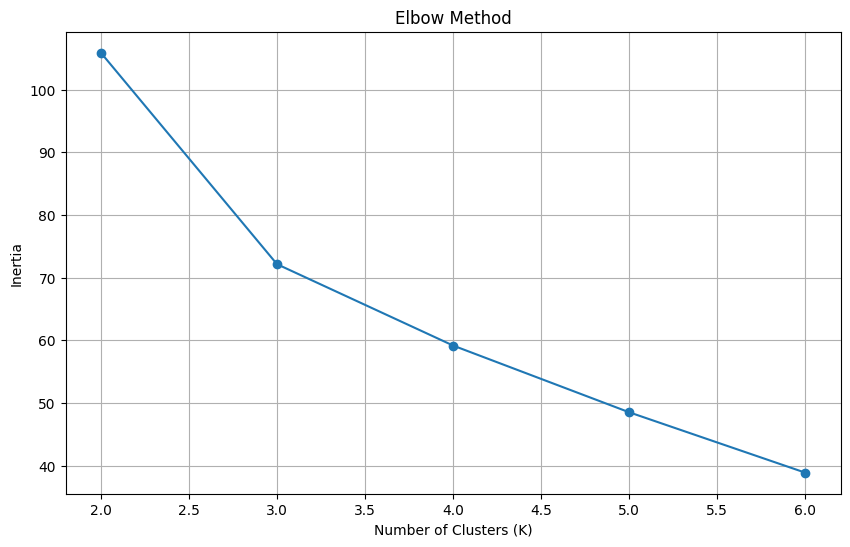

In [ ]:
plt.figure(
    figsize=(10, 6)
)

plt.plot(
    list(K_range),
    inertia,
    marker="o"
)

plt.xlabel(
    "Number of Clusters (K)"
)

plt.ylabel(
    "Inertia"
)

plt.title(
    "Elbow Method"
)

plt.grid(True)

plt.show()

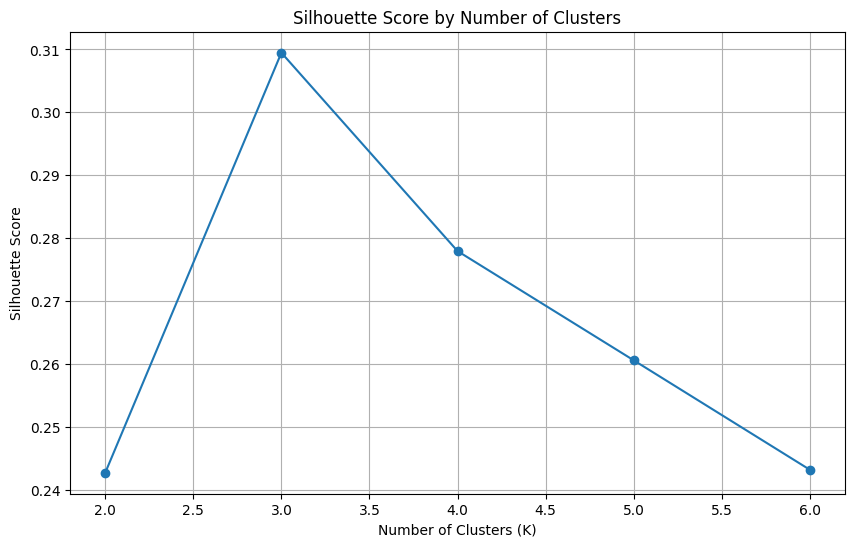

K=2: Silhouette=0.2427
K=3: Silhouette=0.3095
K=4: Silhouette=0.2779
K=5: Silhouette=0.2606
K=6: Silhouette=0.2432


In [ ]:
plt.figure(
    figsize=(10, 6)
)

plt.plot(
    list(K_range),
    silhouette_scores,
    marker="o"
)

plt.xlabel(
    "Number of Clusters (K)"
)

plt.ylabel(
    "Silhouette Score"
)

plt.title(
    "Silhouette Score by Number of Clusters"
)

plt.grid(True)

plt.show()

for k, score in zip(
    K_range,
    silhouette_scores
):

    print(
        f"K={k}: "
        f"Silhouette={score:.4f}"
    )

In [ ]:
best_k = list(K_range)[
    np.argmax(
        silhouette_scores
    )
]

print(
    "Recommended number of clusters:",
    best_k
)

Recommended number of clusters: 3


Train final K-Means

In [ ]:
# ============================================================
# FINAL K-MEANS MODEL
# ============================================================

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=50
)

master["cluster"] = (
    kmeans.fit_predict(
        X_scaled_cleaned
    )
)

print(
    master["cluster"]
    .value_counts()
    .sort_index()
)

cluster
0     3
1    10
2     3
Name: count, dtype: int64


In [ ]:
cluster_profile = (
    master
    .groupby("cluster")[ml_features]
    .mean()
)

display(
    cluster_profile
)

,gdp_per_capita,income_mean,income_median,poverty_score,inequality_score,unemployment_score,labour_participation_rate,forest_per_population,treated_water_access,water_pressure_score
cluster,,,,,,,,,,
0,"71,839.199","13,010.333","10,091.000",-1.000,-0.370,-2.967,75.733,0.012,99.633,-606.333
1,"41,608.616","6,989.700","5,596.100",-5.070,-0.347,-3.540,65.780,0.225,99.110,-230.400
2,"31,879.862","5,837.667","4,389.667",-14.567,-0.387,-5.033,64.300,0.998,79.367,-259.333


In [ ]:
cluster_profile_scaled = (
    pd.DataFrame(
        scaler.transform(
            cluster_profile
        ),
        columns=ml_features,
        index=cluster_profile.index
    )
)

display(
    cluster_profile_scaled
)

,gdp_per_capita,income_mean,income_median,poverty_score,inequality_score,unemployment_score,labour_participation_rate,forest_per_population,treated_water_access,water_pressure_score
cluster,,,,,,,,,,
0,1.009,1.903,1.870,1.030,-0.403,0.468,1.480,-0.687,0.515,-1.001
1,-0.147,-0.340,-0.297,0.206,0.442,0.108,-0.281,-0.227,0.450,0.253
2,-0.519,-0.769,-0.879,-1.717,-1.070,-0.828,-0.543,1.444,-2.014,0.157


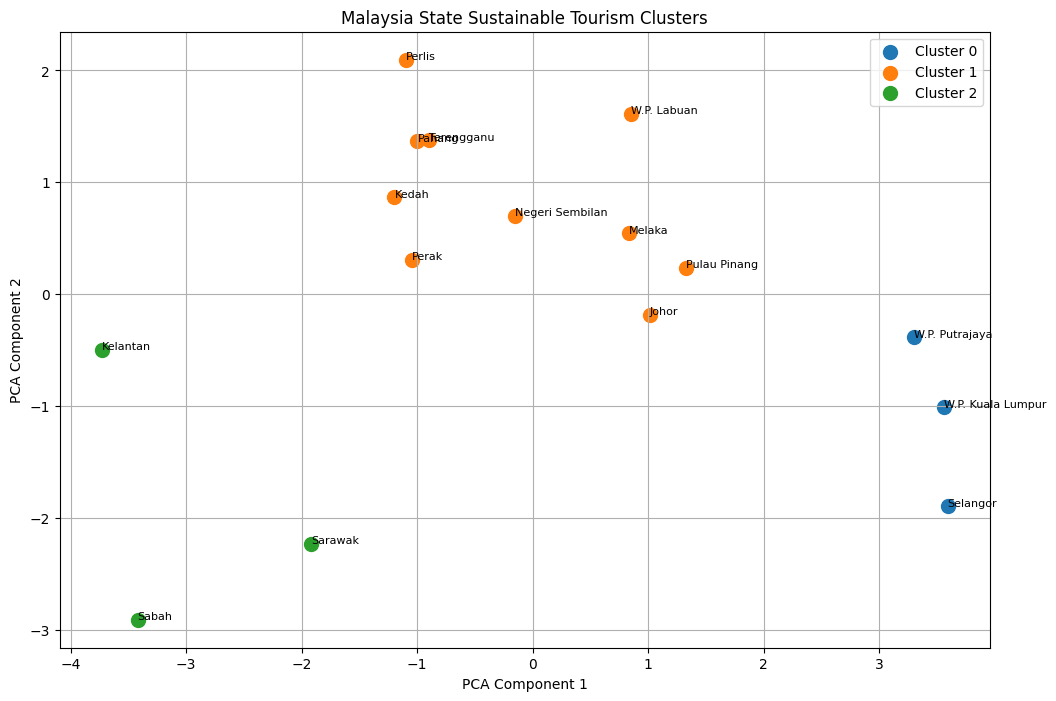

In [ ]:
# ============================================================
# PCA
# ============================================================

pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(
    X_scaled_cleaned
)

master["PCA1"] = X_pca[:, 0]
master["PCA2"] = X_pca[:, 1]

plt.figure(
    figsize=(12, 8)
)

for cluster in sorted(
    master["cluster"].unique()
):

    subset = master[
        master["cluster"] == cluster
    ]

    plt.scatter(
        subset["PCA1"],
        subset["PCA2"],
        label=f"Cluster {cluster}",
        s=100
    )

    for _, row in subset.iterrows():

        plt.annotate(
            row["state"],
            (
                row["PCA1"],
                row["PCA2"]
            ),
            fontsize=8
        )

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")

plt.title(
    "Malaysia State Sustainable Tourism Clusters"
)

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
cluster_states = master[
    [
        "state",
        "cluster"
    ]
].sort_values(
    "cluster"
)

display(
    cluster_states
)

,state,cluster
13,W.P. Kuala Lumpur,0
15,W.P. Putrajaya,0
9,Selangor,0
0,Johor,1
6,Pulau Pinang,1
1,Kedah,1
3,Melaka,1
4,Negeri Sembilan,1
14,W.P. Labuan,1
7,Perak,1


In [ ]:
# ============================================================
# DIMENSION SCORES
# ============================================================

from sklearn.preprocessing import MinMaxScaler

dimension_scaler = MinMaxScaler()

master["economic_score"] = (
    dimension_scaler.fit_transform(
        master[
            [
                "gdp_per_capita",
                "income_mean",
                "income_median"
            ]
        ]
    ).mean(axis=1) * 100
)

In [ ]:
master["social_score"] = (
    dimension_scaler.fit_transform(
        master[
            [
                "poverty_score",
                "inequality_score",
                "unemployment_score",
                "labour_participation_rate"
            ]
        ]
    ).mean(axis=1) * 100
)

In [ ]:
master["environment_score"] = (
    dimension_scaler.fit_transform(
        master[
            [
                "forest_per_population",
                "treated_water_access",
                "water_pressure_score"
            ]
        ]
    ).mean(axis=1) * 100
)

In [ ]:
# ============================================================
# SUSTAINABLE TOURISM READINESS INDEX
# ============================================================

master["readiness_score"] = (
    master["economic_score"] * 0.3333
    +
    master["social_score"] * 0.3333
    +
    master["environment_score"] * 0.3334
)

master["readiness_score"] = (
    master["readiness_score"]
    .round(2)
)

display(
    master
    .sort_values(
        "readiness_score",
        ascending=False
    )[
        [
            "state",
            "economic_score",
            "social_score",
            "environment_score",
            "readiness_score"
        ]
    ]
)

,state,economic_score,social_score,environment_score,readiness_score
13,W.P. Kuala Lumpur,99.426,61.682,60.675,73.930
15,W.P. Putrajaya,73.040,82.105,60.674,71.940
14,W.P. Labuan,50.462,63.031,66.291,59.930
9,Selangor,72.918,71.345,33.816,59.360
6,Pulau Pinang,43.044,64.545,58.695,55.430
5,Pahang,16.467,70.777,77.941,55.060
3,Melaka,34.796,65.558,62.470,54.280
0,Johor,36.909,61.760,55.303,51.320
10,Terengganu,25.750,55.872,67.148,49.590
4,Negeri Sembilan,23.984,53.435,63.880,47.100


In [ ]:
# ============================================================
# READINESS CATEGORY
# ============================================================

def readiness_category(score):

    if score >= 70:
        return "High"

    elif score >= 50:
        return "Medium"

    else:
        return "Emerging"


master["readiness_category"] = (
    master["readiness_score"]
    .apply(readiness_category)
)

display(
    master[
        [
            "state",
            "readiness_score",
            "readiness_category"
        ]
    ].sort_values(
        "readiness_score",
        ascending=False
    )
)

,state,readiness_score,readiness_category
13,W.P. Kuala Lumpur,73.930,High
15,W.P. Putrajaya,71.940,High
14,W.P. Labuan,59.930,Medium
9,Selangor,59.360,Medium
6,Pulau Pinang,55.430,Medium
5,Pahang,55.060,Medium
3,Melaka,54.280,Medium
0,Johor,51.320,Medium
10,Terengganu,49.590,Emerging
4,Negeri Sembilan,47.100,Emerging


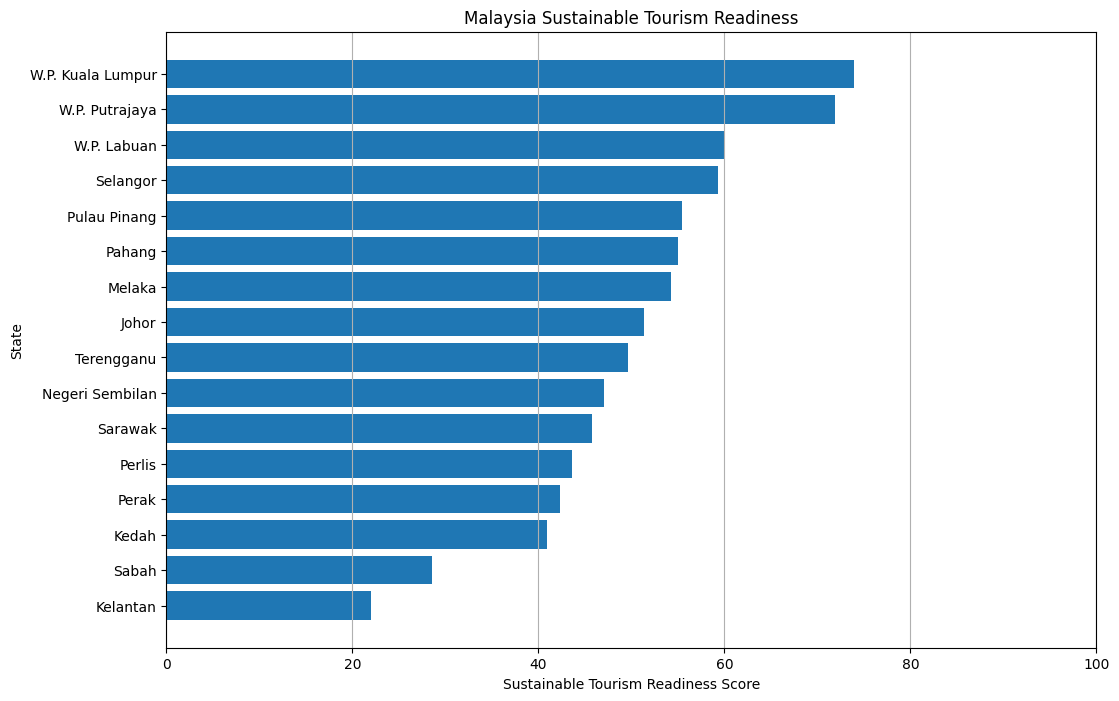

In [ ]:
ranking = (
    master[
        [
            "state",
            "readiness_score"
        ]
    ]
    .sort_values(
        "readiness_score",
        ascending=True
    )
)

plt.figure(
    figsize=(12, 8)
)

plt.barh(
    ranking["state"],
    ranking["readiness_score"]
)

plt.xlabel(
    "Sustainable Tourism Readiness Score"
)

plt.ylabel(
    "State"
)

plt.title(
    "Malaysia Sustainable Tourism Readiness"
)

plt.xlim(
    0,
    100
)

plt.grid(
    axis="x"
)

plt.show()

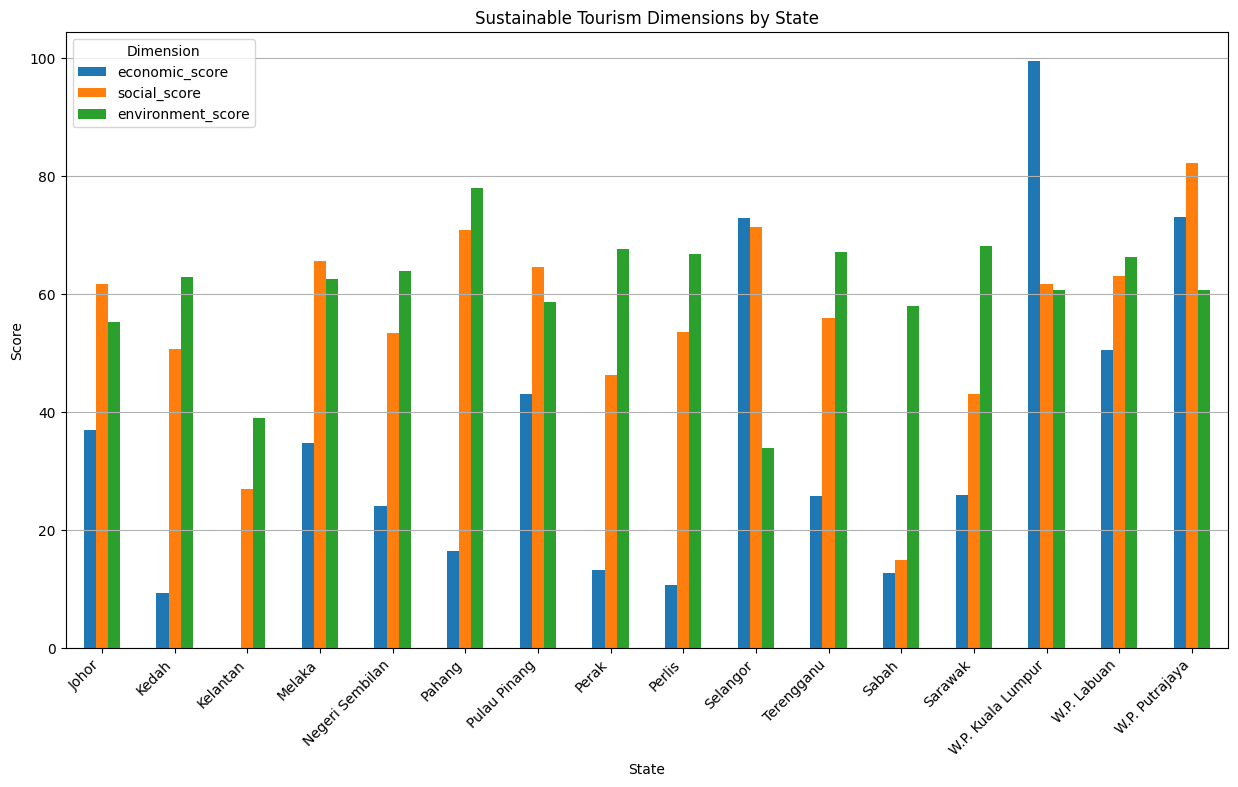

In [ ]:
score_columns = [
    "economic_score",
    "social_score",
    "environment_score"
]

score_by_state = master[
    ["state"] + score_columns
].set_index("state")

score_by_state.plot(
    kind="bar",
    figsize=(15, 8)
)

plt.ylabel(
    "Score"
)

plt.xlabel(
    "State"
)

plt.title(
    "Sustainable Tourism Dimensions by State"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y"
)

plt.legend(
    title="Dimension"
)

plt.show()

ML classification

In [ ]:
# ============================================================
# RANDOM FOREST CLASSIFICATION
# ============================================================

rf_features = ml_features

X_rf = master[
    rf_features
]

y_rf = master[
    "cluster"
]

In [ ]:
rf = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    class_weight="balanced"
)

rf.fit(
    X_rf,
    y_rf
)

print(
    "Random Forest trained."
)

Random Forest trained.


In [ ]:
importance = pd.DataFrame({

    "feature":
    rf_features,

    "importance":
    rf.feature_importances_

})

importance = (
    importance
    .sort_values(
        "importance",
        ascending=False
    )
)

display(
    importance
)

,feature,importance
3,poverty_score,0.200
4,inequality_score,0.150
2,income_median,0.138
6,labour_participation_rate,0.134
8,treated_water_access,0.125
1,income_mean,0.121
7,forest_per_population,0.060
0,gdp_per_capita,0.028
5,unemployment_score,0.025
9,water_pressure_score,0.020


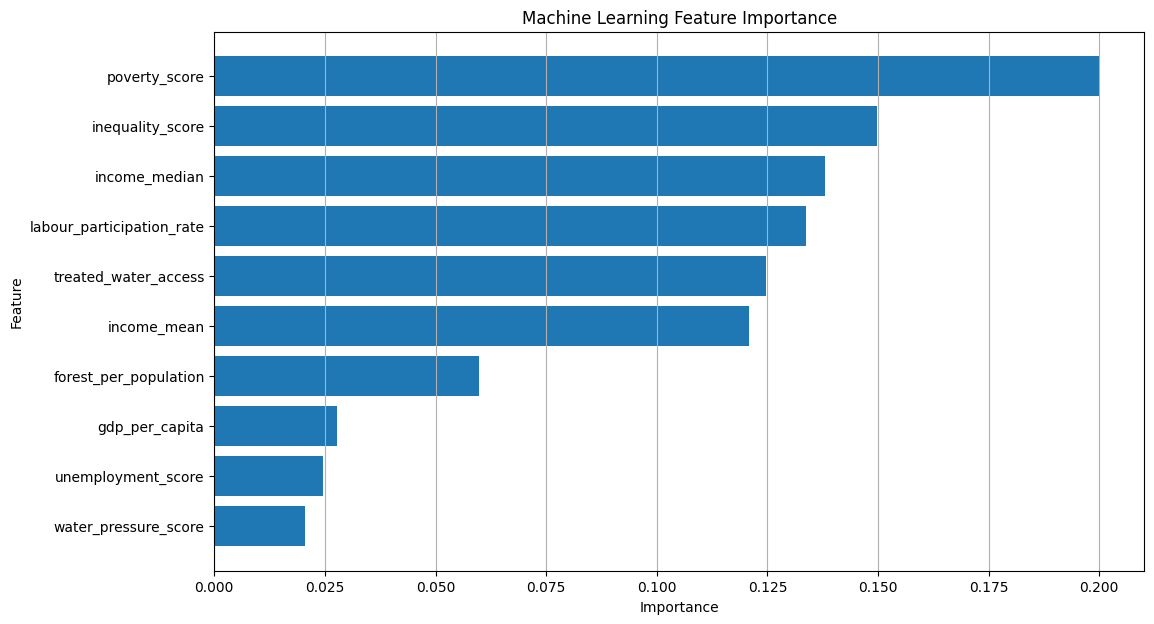

In [ ]:
plt.figure(
    figsize=(12, 7)
)

plt.barh(
    importance["feature"],
    importance["importance"]
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Machine Learning Feature Importance"
)

plt.gca().invert_yaxis()

plt.grid(
    axis="x"
)

plt.show()

In [ ]:
# ============================================================
# CLUSTER INTERPRETATION
# ============================================================

cluster_scores = (
    master
    .groupby("cluster")
    [
        [
            "economic_score",
            "social_score",
            "environment_score",
            "readiness_score"
        ]
    ]
    .mean()
)

display(
    cluster_scores
)

,economic_score,social_score,environment_score,readiness_score
cluster,,,,
0,81.795,71.711,51.722,68.410
1,26.456,58.538,64.886,49.961
2,12.905,28.328,55.027,32.090


In [ ]:
cluster_names = {}

for cluster in cluster_scores.index:

    score = (
        cluster_scores
        .loc[
            cluster,
            "readiness_score"
        ]
    )

    if score >= 70:

        cluster_names[
            cluster
        ] = "High Readiness"

    elif score >= 50:

        cluster_names[
            cluster
        ] = "Moderate Readiness"

    else:

        cluster_names[
            cluster
        ] = "Emerging Readiness"


master["cluster_name"] = (
    master["cluster"]
    .map(cluster_names)
)

display(
    master[
        [
            "state",
            "cluster",
            "cluster_name"
        ]
    ]
)

,state,cluster,cluster_name
0,Johor,1,Emerging Readiness
1,Kedah,1,Emerging Readiness
2,Kelantan,2,Emerging Readiness
3,Melaka,1,Emerging Readiness
4,Negeri Sembilan,1,Emerging Readiness
5,Pahang,1,Emerging Readiness
6,Pulau Pinang,1,Emerging Readiness
7,Perak,1,Emerging Readiness
8,Perlis,1,Emerging Readiness
9,Selangor,0,Moderate Readiness


Final master dataset

In [ ]:
# ============================================================
# FINAL DATASET
# ============================================================

final_columns = [

    "state",

    # Raw socioeconomic
    "income_mean",
    "income_median",
    "expenditure_mean",
    "gini",
    "poverty",

    # Population
    "population",

    # Tourism pressure
    "tourist_arrivals",
    "arrivals_per_1000_residents",

    # Economic
    "gdp",
    "gdp_per_capita",

    # Labour
    "unemployment_rate",
    "labour_participation_rate",

    # Environment
    "forest_reserve_area",
    "treated_water_access",
    "domestic_water_consumption",
    "nondomestic_water_consumption",

    # Scores
    "economic_score",
    "social_score",
    "environment_score",
    "readiness_score",
    "readiness_category",

    # ML
    "cluster",
    "cluster_name"
]

final_columns = [
    c for c in final_columns
    if c in master.columns
]

final_dataset = master[
    final_columns
].copy()

tourism_pressure = final_dataset[
    [
        "state",
        "population",
        "tourist_arrivals",
        "arrivals_per_1000_residents",
        "readiness_score",
        "readiness_category"
    ]
].copy()

display(
    final_dataset
    .sort_values(
        "readiness_score",
        ascending=False
    )
)

,state,income_mean,income_median,expenditure_mean,gini,poverty,population,tourist_arrivals,arrivals_per_1000_residents,gdp,gdp_per_capita,unemployment_rate,labour_participation_rate,forest_reserve_area,treated_water_access,domestic_water_consumption,nondomestic_water_consumption,economic_score,social_score,environment_score,readiness_score,readiness_category,cluster,cluster_name
13,W.P. Kuala Lumpur,13325,10234,7823,0.380,1.400,"1,961.200",0.000,0.000,"240,517.538","122,637.945",3.800,72.700,68.000,99.550,389.500,234.500,99.426,61.682,60.675,73.930,High,0,Moderate Readiness
15,W.P. Putrajaya,13473,10056,8897,0.368,0.100,117.000,0.000,0.000,"61,746.204","38,249.522",1.300,77.700,0.000,99.550,389.500,234.500,73.040,82.105,60.674,71.940,High,0,Moderate Readiness
14,W.P. Labuan,8250,6904,4176,0.300,2.500,96.900,"6,375.000",65.789,"7,962.511","82,172.456",6.900,67.400,0.000,100.000,19.000,33.000,50.462,63.031,66.291,59.930,Medium,1,Emerging Readiness
9,Selangor,12233,9983,6770,0.361,1.500,"7,050.300","3,252,445.000",461.320,"385,158.798","54,630.129",3.800,76.800,"250,208.000",99.800,"2,230.000","1,350.000",72.918,71.345,33.816,59.360,Medium,0,Moderate Readiness
6,Pulau Pinang,8267,6502,5322,0.371,2.000,"1,740.900","390,584.000",224.358,"112,281.052","64,495.980",2.700,70.100,"5,387.000",99.900,534.000,334.000,43.044,64.545,58.695,55.430,Medium,1,Emerging Readiness
5,Pahang,5777,4753,4107,0.308,6.300,"1,614.300","1,603.000",0.993,"61,746.204","38,249.522",2.300,64.600,"1,588,298.000",98.000,385.000,283.000,16.467,70.777,77.941,55.060,Medium,1,Emerging Readiness
3,Melaka,8057,6210,5707,0.370,4.200,"1,008.600","49,385.000",48.964,"45,579.035","45,190.398",1.700,69.800,"5,199.000",100.000,228.000,190.000,34.796,65.558,62.470,54.280,Medium,1,Emerging Readiness
0,Johor,8517,6879,5342,0.366,4.600,"4,028.300","9,374,160.000","2,327.076","142,369.692","35,342.376",3.200,71.100,"334,502.000",99.900,867.000,536.000,36.909,61.760,55.303,51.320,Medium,1,Emerging Readiness
10,Terengganu,7248,5878,4796,0.326,6.200,"1,186.600",33.000,0.028,"37,353.840","31,479.724",3.500,59.800,"540,309.000",96.000,286.000,173.000,25.750,55.872,67.148,49.590,Emerging,1,Emerging Readiness
4,Negeri Sembilan,6788,5226,4678,0.369,4.400,"1,207.900","50,226.000",41.581,"50,939.264","42,171.756",3.400,65.100,"155,143.000",99.900,307.000,231.000,23.984,53.435,63.880,47.100,Emerging,1,Emerging Readiness


In [ ]:
# ============================================================
# EXPORT POWER BI FILES
# ============================================================

final_dataset.to_csv(
    "outputs/Malaysia_Sustainable_Tourism_Master.csv",
    index=False
)

tourism_demand_forecast.to_csv(
    "outputs/Tourism_Demand_Forecast.csv",
    index=False
)

tourism_pressure.to_csv(
    "outputs/State_Tourism_Pressure.csv",
    index=False
)

importance.to_csv(
    "outputs/ML_Feature_Importance.csv",
    index=False
)

cluster_profile.to_csv(
    "outputs/ML_Cluster_Profile.csv"
)

cluster_states.to_csv(
    "outputs/ML_State_Clusters.csv",
    index=False
)

results = pd.DataFrame({
    "Metric": [
        "Number of states",
        "Number of ML clusters",
        "Silhouette score"
    ],

    "Value": [
        master["state"].nunique(),
        best_k,
        max(silhouette_scores)
    ]
})

results.to_csv(
    "outputs/ML_Model_Summary.csv",
    index=False
)

print(
    "Power BI files created."
)

Power BI files created.


In [ ]:
# ============================================================
# ZIP ALL OUTPUTS
# ============================================================

import shutil

shutil.make_archive(
    "Malaysia_Sustainable_Tourism_Project",
    "zip",
    "outputs"
)

print(
    "ZIP created:"
)

print(
    "Malaysia_Sustainable_Tourism_Project.zip"
)

ZIP created:
Malaysia_Sustainable_Tourism_Project.zip


In [ ]:
# ============================================================
# EXPORT READY FOR LOCAL BI TOOLING
# ============================================================

print("Final dataset exported to outputs/Malaysia_Sustainable_Tourism_Master.csv")
print("Model summary exported to outputs/ML_Model_Summary.csv")

Final dataset exported to outputs/Malaysia_Sustainable_Tourism_Master.csv
Model summary exported to outputs/ML_Model_Summary.csv
